# 04 — LightGBM: diagnosis and tuning (Hadiqa)

Development set only (5-fold CV); the test set is not used.

**Scripts run, this notebook explains.** Every number here is produced by
`tuning/lightgbm.py` and saved in `tuning/results/lightgbm/`; this notebook only
reads those files and comments on them (no training here).

| Step | Command (from the project root) | Output |
|---|---|---|
| 1-2. Baseline + diagnosis | `python3 -m tuning.lightgbm baseline` | `baseline.csv` |
| 3. Validation curves | `python3 -m tuning.lightgbm curves` | `curves.csv`, `curves/*.png` |
| 4. Tuning v2 | `python3 -m tuning.tune --version v2 --model lgbm`, then `python3 -m tuning.lightgbm baseline` | `tuning/results/v2/best_params.json`, `baseline.csv` |

Tuning v1 = Soumaya's first Optuna run: `tuning/results/v1/best_params.json`
(git tag `baseline-v1`): 350 trees, learning_rate 0.016, 27 leaves,
min_child_samples 36, subsample 0.69, colsample_bytree 0.92, almost no L1 / L2
penalty, scale_pos_weight 1.32.

The starting point is **LightGBM with its default parameters, without class
weights**: `LightGBM (balanced)` gave the same ranking and worse probabilities
in `tuning/baseline.py` (PR-AUC 0.716 for both, Brier 0.110 → 0.137, F16), so it
is left out.

Metrics (always mean ± standard deviation over the 5 folds): **PR-AUC** (main
metric; 0.239 = the share of high earners = the floor), **ROC-AUC**, **Brier**
(quality of the probabilities, lower is better).

Hyperparameters studied: `learning_rate` × `n_estimators`, `num_leaves`,
`max_depth`, `min_child_samples`, `subsample`, `colsample_bytree`, `reg_alpha`,
`reg_lambda`, `scale_pos_weight`.

Course sessions used: **S2** L1 / L2 penalties; **S4** gradient boosting;
**S5** Pipeline, cross-validation, validation curves, bias–variance; **S6**
PR-AUC and class weights; **S7** Brier score and calibration.

In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
RESULTS = ROOT / "tuning" / "results" / "lightgbm"
COLS = ["train PR-AUC", "val PR-AUC", "val PR-AUC std", "gap PR-AUC",
        "val ROC-AUC", "val ROC-AUC std", "val Brier", "val Brier std"]

## 1. Baseline

**How LightGBM "minimises the loss" (S4, gradient boosting).** Like the
logistic regression, LightGBM minimises **the log-loss**; unlike it, the model
is not a weighted sum of columns but a **sum of trees**, built one after the
other:

1. start from the base rate (every person gets the score of 24%);
2. for each person, compute the **gradient** of the log-loss: roughly
   *true label − current predicted probability*, i.e. where and how much the
   current model is wrong;
3. fit a small tree to these gradients, and **add** its output to the score,
   multiplied by the `learning_rate` (a small step in the right direction);
4. repeat `n_estimators` times. The probability is the sigmoid of the sum.

So:
- **`learning_rate` × `n_estimators`** = how far the model goes in fitting the
  training data. A small rate needs more trees; too many steps = overfitting.
  This is the opposite of the random forest, where trees are averaged and more
  trees never hurt (F36): in boosting, **each tree is a step**.
- **Tree complexity:** LightGBM grows each tree **leaf by leaf** (it always
  splits the leaf that reduces the loss most, wherever it is), so the main
  limit is `num_leaves` (default 31); `max_depth` (default: no limit) and
  `min_child_samples` (default: 20 people per leaf) are extra limits.
- **Randomness:** `subsample` (share of rows per tree) and `colsample_bytree`
  (share of columns per tree), as in the forest.
- **Penalties:** `reg_alpha` (L1) and `reg_lambda` (L2) on the leaf values, the
  same idea as S2 but on the leaves instead of the weights.
- **Class weight:** `scale_pos_weight` multiplies the loss of the high earners
  (S6).

Because the objective is the log-loss, the probabilities are usually good
(S7); because the model is a sum of trees, it builds curves and interactions by
itself (why the engineered features do not help it, F15).

Four starting points, from the floor to the tuned v1 model (5-fold CV):

In [2]:
baseline = pd.read_csv(RESULTS / "baseline.csv")
baseline[["experiment", *COLS]].round(4)

,experiment,train PR-AUC,val PR-AUC,val PR-AUC std,gap PR-AUC,val ROC-AUC,val ROC-AUC std,val Brier,val Brier std
0,Dummy (predicts the base rate),0.2394,0.2394,0.0000,-0.0000,0.5000,0.0000,0.1821,0.0000
1,"LightGBM defaults, 6 inputs only",0.7576,0.7155,0.0107,0.0420,0.8916,0.0045,0.1101,0.0021
2,LightGBM defaults + engineered features,0.7574,0.7155,0.0109,0.0419,0.8917,0.0045,0.1101,0.0021
3,LightGBM tuned v1,0.7405,0.7190,0.0116,0.0215,0.8928,0.0047,0.1112,0.0022
4,LightGBM tuned v2,0.7341,0.7189,0.0126,0.0152,0.8928,0.0050,0.1096,0.0024


PR-AUC: higher is better; 0.239 is the floor (the share of high earners).
Brier: quality of the probabilities, lower is better (0.182 = always predicting
the base rate).

## 2. Diagnosis: train vs validation (overfitting or underfitting?)

1. **Mild overfitting at the defaults, not a problem.** Train 0.757,
   validation 0.7155 ± 0.011: gap 0.042, about four times the fold-to-fold
   noise. Compare with the random forest at its defaults (gap 0.33, F32) and
   after tuning v2 (0.039, F36), and with the logistic regression (0.0014,
   F37). One hundred small trees of 31 leaves already start close to the right
   place.
2. **The engineered features add nothing:** 0.7155 with the 6 inputs only and
   0.7155 with the engineered columns (train 0.758 vs 0.757). The trees build
   these curves and thresholds by themselves (F15, now also on train vs
   validation).
3. **Tuning v1 halves the gap but adds little:** train 0.740, validation
   0.7190 ± 0.012, gap 0.022. The gain (+0.0035) is a third of the fold
   standard deviation. Its Brier is slightly worse (0.1101 → 0.1112), which
   fits its mild class weight (`scale_pos_weight` 1.32, see section 3).
4. **No bias problem either:** LightGBM is the best of the three model
   families on the same folds (logistic regression 0.708, random forest v2
   0.715), and it gets there with a moderate gap.

**Answer: a little variance, no real bias; the model is at the ceiling of the
6 inputs.** Questions for the validation curves: how many trees for each
learning rate? Which limits (leaves, depth, leaf size, penalties) close the gap,
and does validation go up when they do? Does row or column sampling help, as in
the forest? What does class weighting cost?

## 3. Validation curves on the key hyperparameters

One setting changes, the others stay at the LightGBM defaults (100 trees,
learning_rate 0.1, 31 leaves, no depth limit, 20 people per leaf, all rows and
columns, no penalty, no class weight), with `subsample_freq=1` as in
`src/models.py` (without it, `subsample` is ignored).

`learning_rate` and `n_estimators` cannot be read separately (section 1), so
they are one curve: **4 learning rates × 7 numbers of trees** (25 to 1,600).

val PR-AUC: learning_rate (rows) x n_estimators (columns)


n_estimators,25,50,100,200,400,800,1600
learning_rate,,,,,,,
0.01,0.6863,0.6954,0.7027,0.7095,0.7162,0.7163,0.7139
0.03,0.6999,0.7063,0.7133,0.7170,0.7155,0.7118,0.7033
0.10,0.7117,0.7165,0.7155,0.7116,0.7041,0.6916,0.6719
0.30,0.7120,0.7088,0.7009,0.6862,0.6491,0.5951,0.5853


gap PR-AUC: learning_rate (rows) x n_estimators (columns)


n_estimators,25,50,100,200,400,800,1600
learning_rate,,,,,,,
0.01,0.0097,0.0096,0.0111,0.0140,0.0207,0.0354,0.0595
0.03,0.0100,0.0125,0.0183,0.0275,0.0481,0.0793,0.1260
0.10,0.0160,0.0246,0.0419,0.0714,0.1142,0.1736,0.2437
0.30,0.0362,0.0590,0.0964,0.1489,0.1931,0.1844,0.2016


val Brier: learning_rate (rows) x n_estimators (columns)


n_estimators,25,50,100,200,400,800,1600
learning_rate,,,,,,,
0.01,0.1555,0.1391,0.1227,0.1130,0.1101,0.1100,0.1105
0.03,0.1287,0.1158,0.1107,0.1099,0.1102,0.1111,0.1131
0.10,0.1113,0.1099,0.1101,0.1110,0.1127,0.1161,0.1220
0.30,0.1106,0.1114,0.1131,0.1160,0.1222,0.1472,0.1751


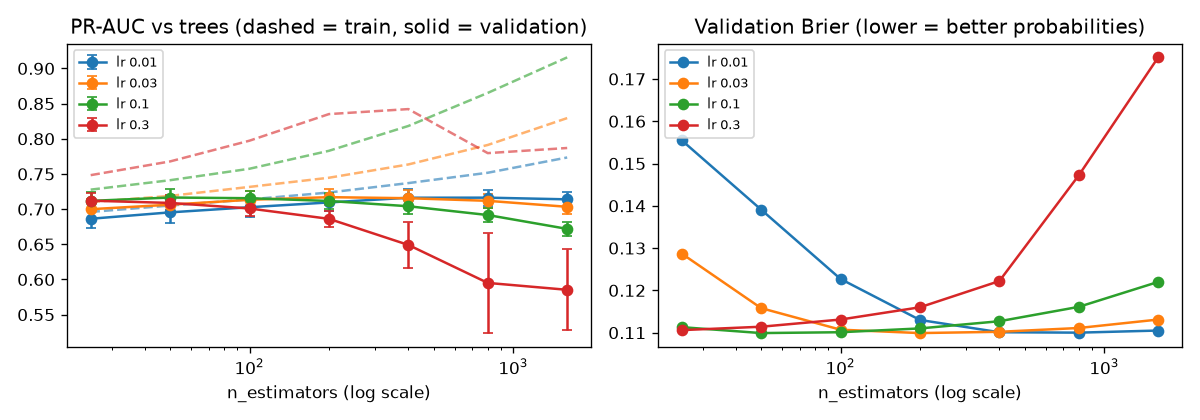

In [3]:
curves = pd.read_csv(RESULTS / "curves.csv")
lr = curves[curves["param"] == "learning_rate"]
for metric in ["val PR-AUC", "gap PR-AUC", "val Brier"]:
    print(f"{metric}: learning_rate (rows) x n_estimators (columns)")
    display(lr.pivot(index="learning_rate", columns="n_estimators", values=metric).round(4))
display(Image(str(RESULTS / "curves" / "learning_rate.png")))

num_leaves


,value,train PR-AUC,val PR-AUC,val PR-AUC std,gap PR-AUC,val ROC-AUC,val ROC-AUC std,val Brier,val Brier std
0,4,0.7153,0.7106,0.0119,0.0047,0.8900,0.0051,0.1110,0.0023
1,8,0.7269,0.7155,0.0131,0.0114,0.8914,0.0049,0.1102,0.0023
2,16,0.7403,0.7169,0.0123,0.0235,0.8920,0.0048,0.1099,0.0023
3,31,0.7574,0.7155,0.0109,0.0419,0.8917,0.0045,0.1101,0.0021
4,63,0.7862,0.7109,0.0106,0.0752,0.8900,0.0044,0.1111,0.0021
5,127,0.8262,0.7049,0.0115,0.1213,0.8869,0.0043,0.1128,0.0021
6,255,0.8765,0.6939,0.0103,0.1826,0.8826,0.0039,0.1158,0.0021


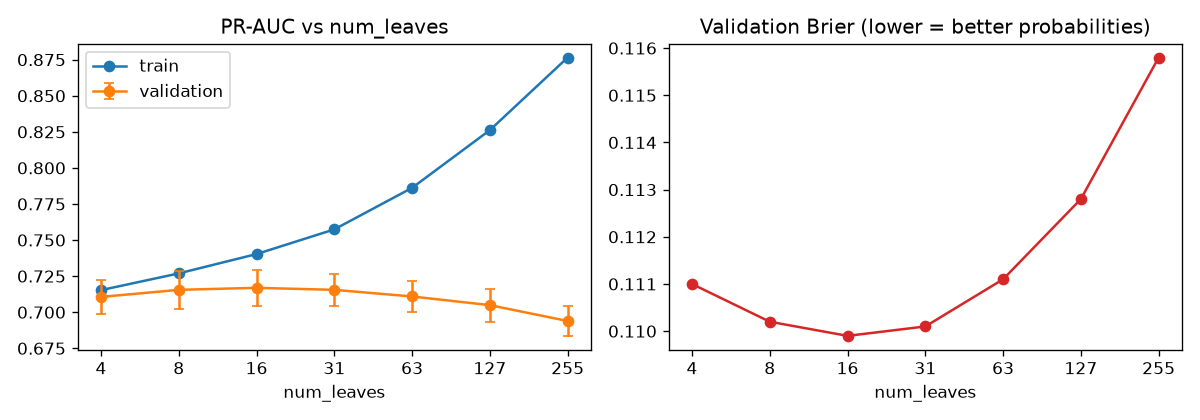

max_depth


,value,train PR-AUC,val PR-AUC,val PR-AUC std,gap PR-AUC,val ROC-AUC,val ROC-AUC std,val Brier,val Brier std
7,2,0.7138,0.7091,0.0125,0.0047,0.8894,0.0051,0.1115,0.0023
8,3,0.7246,0.7149,0.0125,0.0097,0.8912,0.0050,0.1104,0.0023
9,4,0.7342,0.7170,0.0112,0.0171,0.8920,0.0046,0.1099,0.0022
10,6,0.7513,0.7166,0.0111,0.0348,0.8921,0.0046,0.1099,0.0022
11,8,0.7556,0.7152,0.0113,0.0404,0.8917,0.0046,0.1102,0.0022
12,12,0.7578,0.7152,0.0116,0.0427,0.8917,0.0044,0.1101,0.0021
13,-1,0.7574,0.7155,0.0109,0.0419,0.8917,0.0045,0.1101,0.0021


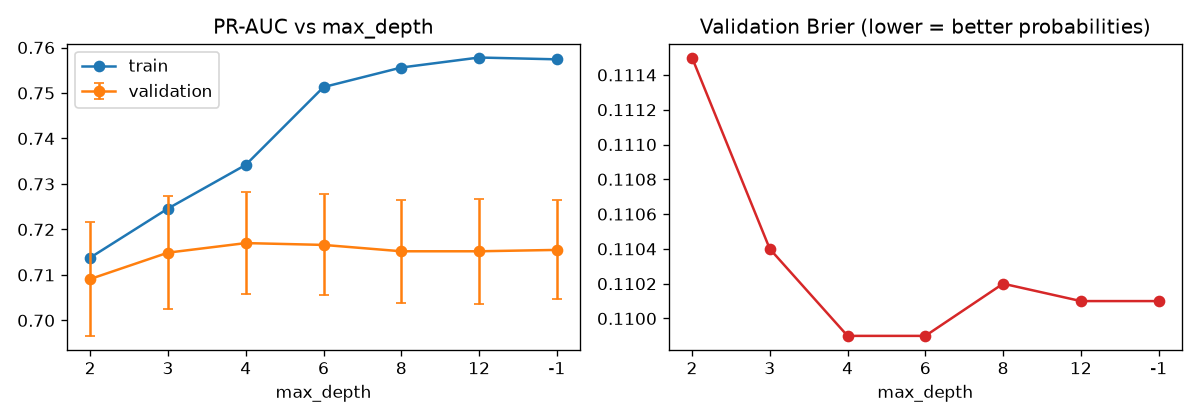

min_child_samples


,value,train PR-AUC,val PR-AUC,val PR-AUC std,gap PR-AUC,val ROC-AUC,val ROC-AUC std,val Brier,val Brier std
14,5,0.7615,0.7141,0.0121,0.0474,0.8912,0.0048,0.1103,0.0023
15,10,0.7607,0.7142,0.0098,0.0465,0.8915,0.0045,0.1102,0.0021
16,20,0.7574,0.7155,0.0109,0.0419,0.8917,0.0045,0.1101,0.0021
17,50,0.7542,0.7162,0.0115,0.0380,0.8918,0.0045,0.1101,0.0021
18,100,0.7506,0.7151,0.0113,0.0355,0.8915,0.0044,0.1102,0.0022
19,200,0.7463,0.7154,0.0122,0.0309,0.8916,0.0046,0.1102,0.0022
20,500,0.7398,0.7154,0.0119,0.0244,0.8919,0.0046,0.1101,0.0022


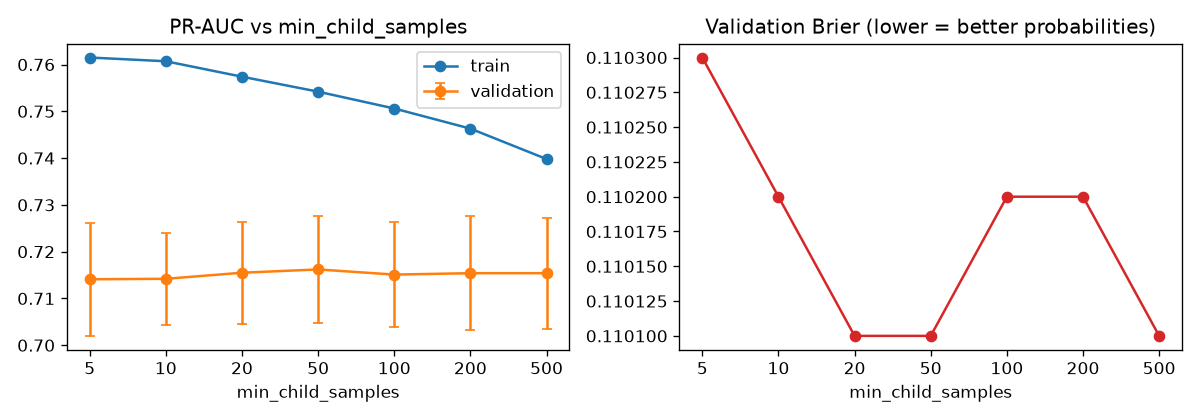

subsample


,value,train PR-AUC,val PR-AUC,val PR-AUC std,gap PR-AUC,val ROC-AUC,val ROC-AUC std,val Brier,val Brier std
21,0.3,0.7550,0.7117,0.0113,0.0432,0.8902,0.0047,0.1111,0.0023
22,0.5,0.7581,0.7135,0.0120,0.0445,0.8910,0.0046,0.1106,0.0023
23,0.7,0.7599,0.7164,0.0115,0.0435,0.8920,0.0045,0.1101,0.0022
24,0.9,0.7600,0.7155,0.0110,0.0444,0.8919,0.0048,0.1101,0.0022
25,1.0,0.7574,0.7155,0.0109,0.0419,0.8917,0.0045,0.1101,0.0021


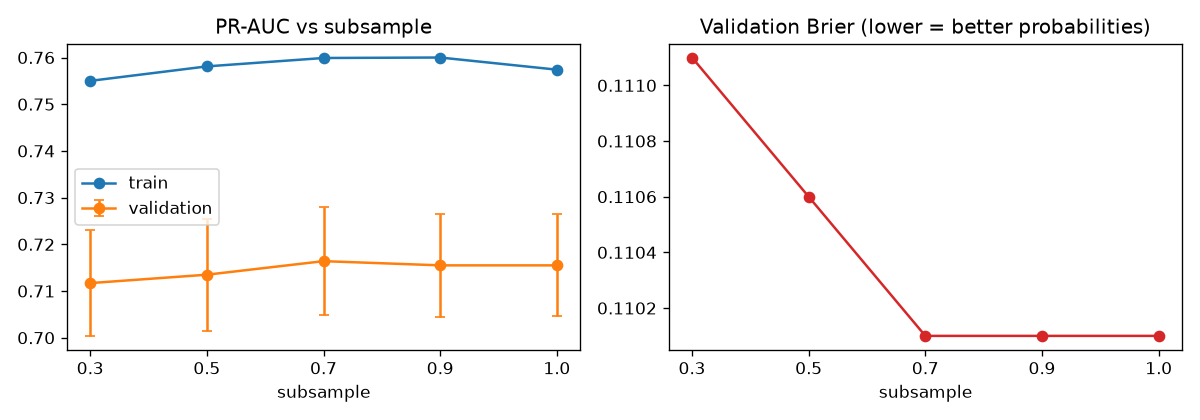

colsample_bytree


,value,train PR-AUC,val PR-AUC,val PR-AUC std,gap PR-AUC,val ROC-AUC,val ROC-AUC std,val Brier,val Brier std
26,0.2,0.7388,0.7162,0.0129,0.0226,0.8920,0.0052,0.1100,0.0025
27,0.4,0.7511,0.7181,0.0129,0.0331,0.8926,0.0051,0.1097,0.0024
28,0.6,0.7559,0.7167,0.0116,0.0392,0.8922,0.0047,0.1099,0.0022
29,0.8,0.7573,0.7159,0.0112,0.0414,0.8919,0.0047,0.1100,0.0022
30,1.0,0.7574,0.7155,0.0109,0.0419,0.8917,0.0045,0.1101,0.0021


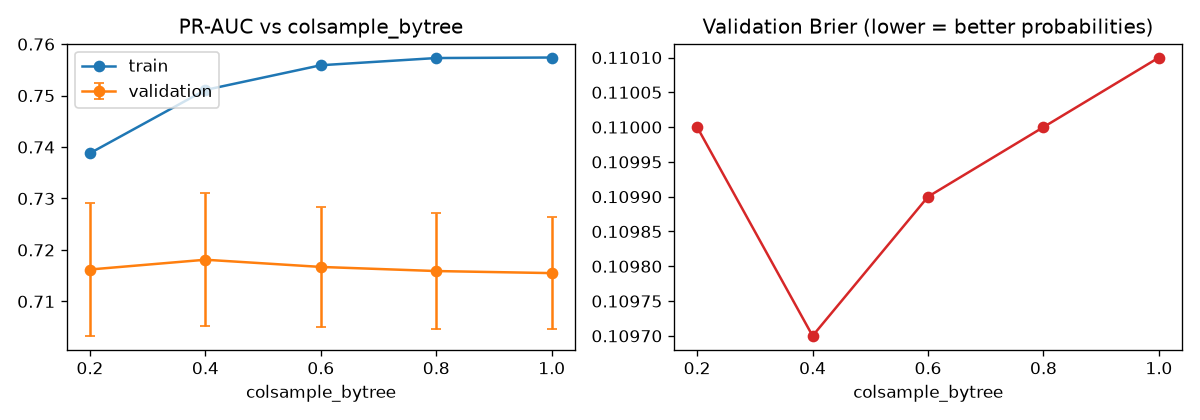

reg_alpha


,value,train PR-AUC,val PR-AUC,val PR-AUC std,gap PR-AUC,val ROC-AUC,val ROC-AUC std,val Brier,val Brier std
31,0,0.7574,0.7155,0.0109,0.0419,0.8917,0.0045,0.1101,0.0021
32,0.01,0.7579,0.7146,0.0118,0.0432,0.8916,0.0047,0.1102,0.0022
33,0.1,0.7580,0.7152,0.0118,0.0428,0.8918,0.0046,0.1101,0.0022
34,1,0.7555,0.7153,0.0110,0.0402,0.8920,0.0042,0.1101,0.0020
35,10,0.7382,0.7168,0.0123,0.0213,0.8920,0.0046,0.1099,0.0022
36,100,0.7091,0.7025,0.0151,0.0066,0.8863,0.0052,0.1128,0.0023


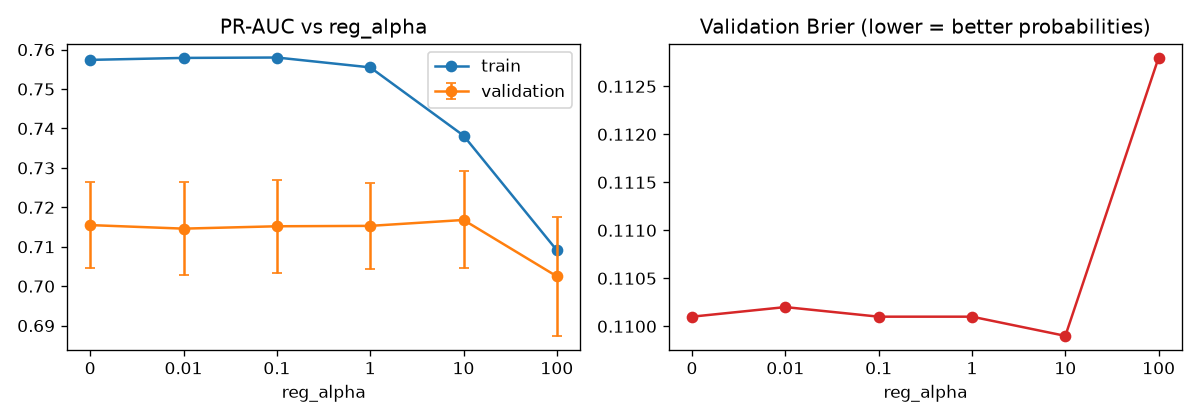

reg_lambda


,value,train PR-AUC,val PR-AUC,val PR-AUC std,gap PR-AUC,val ROC-AUC,val ROC-AUC std,val Brier,val Brier std
37,0,0.7574,0.7155,0.0109,0.0419,0.8917,0.0045,0.1101,0.0021
38,0.01,0.7574,0.7153,0.0111,0.0420,0.8915,0.0045,0.1102,0.0021
39,0.1,0.7584,0.7153,0.0114,0.0431,0.8917,0.0046,0.1101,0.0022
40,1,0.7555,0.7154,0.0116,0.0401,0.8919,0.0047,0.1101,0.0022
41,10,0.7479,0.7163,0.0118,0.0316,0.8922,0.0045,0.1100,0.0022
42,100,0.7372,0.7165,0.0123,0.0207,0.8919,0.0045,0.1099,0.0022


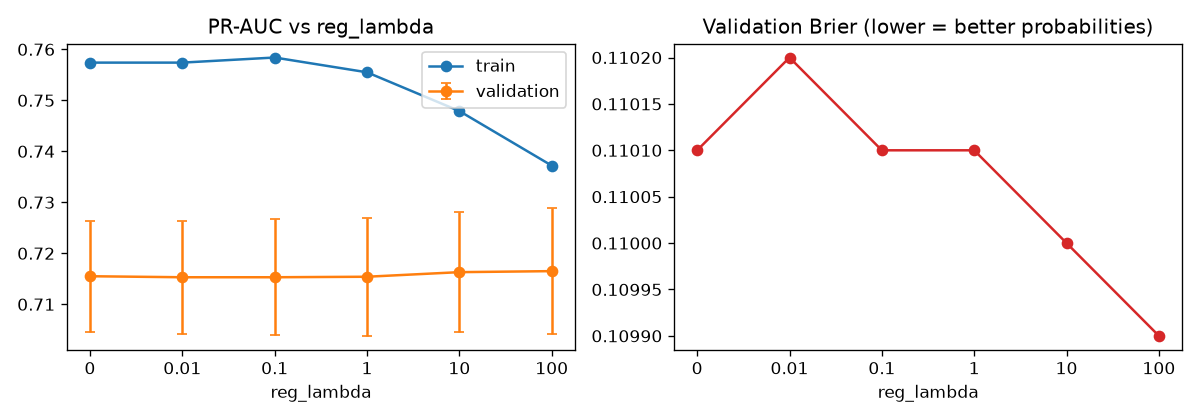

scale_pos_weight


,value,train PR-AUC,val PR-AUC,val PR-AUC std,gap PR-AUC,val ROC-AUC,val ROC-AUC std,val Brier,val Brier std
43,1,0.7574,0.7155,0.0109,0.0419,0.8917,0.0045,0.1101,0.0021
44,1.5,0.7557,0.7156,0.0109,0.0402,0.8915,0.0044,0.1136,0.0021
45,2,0.7544,0.7158,0.0110,0.0387,0.8918,0.0042,0.1200,0.0020
46,3.2,0.7520,0.7160,0.0111,0.0360,0.8915,0.0045,0.1378,0.0020
47,5,0.7489,0.7155,0.0115,0.0334,0.8915,0.0044,0.1616,0.0017


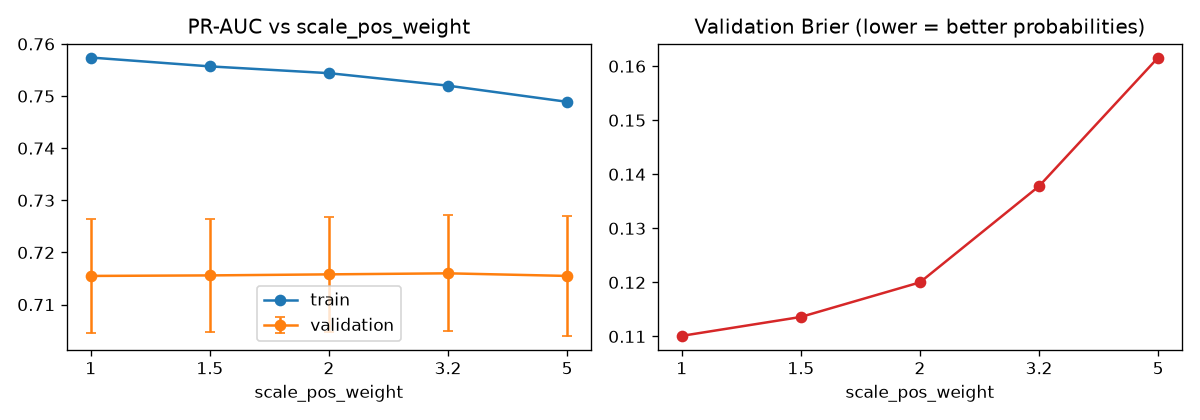

In [4]:
for param, table in curves[curves["param"] != "learning_rate"].groupby("param", sort=False):
    print(param)
    display(table[["value", *COLS]].round(4))
    display(Image(str(RESULTS / "curves" / f"{param}.png")))

### What the curves show

| Setting | Best validation PR-AUC | What the curve shows | Decision for v2 |
|---|---|---|---|
| `learning_rate` × `n_estimators` | 0.7170 (0.03, 200 trees); 0.7165 (0.1, 50); 0.7163 (0.01, 800) | Each rate has its own best number of trees, always at **rate × trees ≈ 5 to 8** (0.01 × 400-800, 0.03 × 200, 0.1 × 50-100). Past it, validation falls and the gap opens: at 0.1 with 1,600 trees, 0.672 (gap 0.24). **A smaller rate gives a wider plateau:** at 0.01, 400 to 1,600 trees all give 0.714-0.716; at 0.1, only 50 to 100. Too few steps underfit: 0.01 × 25 trees → 0.686, Brier 0.156 (the probabilities are still close to the base rate). At 0.3 the fit becomes unstable (below) | Search rate 0.01-0.1 (log) with 100-1,000 trees |
| `num_leaves` | 0.7169 at 16 | The full bias–variance picture: 4 leaves → 0.711, gap 0.005 (a little bias); 255 leaves → 0.694, gap 0.18 (variance). Plateau 8-31 | Search 8-63 |
| `max_depth` | 0.7170 at 4 | Depth 2 underfits (0.709, gap 0.005). From depth 8 it is the same model as no limit, because 31 leaves rarely need more levels. Depth 4-6 halves the gap (0.017-0.035) at the same validation | Search 3-12 (new: not searched in v1) |
| `min_child_samples` | 0.7162 at 50 | Flat: 0.714-0.716 from 5 to 500 people per leaf; the gap closes from 0.047 to 0.024 without any change in validation | Search 10-200 (log) |
| `subsample` | 0.7164 at 0.7 | Flat from 0.7 to 1.0; fewer rows slightly worse (0.3 → 0.712). Unlike the forest (F36), row sampling does not help: the trees are small and the gap is already small | Search 0.7-1.0 |
| `colsample_bytree` | 0.7181 at 0.4 | The highest point of all curves, but +0.0026 over using all columns is a quarter of the fold std. Fewer columns per tree close the gap (0.042 → 0.023 at 0.2) | Search 0.3-1.0 |
| `reg_alpha` (L1) | 0.7168 at 10 | No effect up to 1; at 10 the gap halves (0.021) at the same validation; at 100 the model underfits (0.703, gap 0.007) | Search 0.01-30 (log) |
| `reg_lambda` (L2) | 0.7165 at 100 | No effect up to 1; it only bites from 10, and at 100 it halves the gap (0.021) at the same validation. v1 searched only up to 10 | Search 0.01-100 (log) |
| `scale_pos_weight` | 0.7160 at 3.2 | The ranking does not move (0.7155-0.7160), but the probabilities get worse at every step: Brier 0.110 → 0.114 (1.5) → 0.120 (2) → 0.138 (3.2) → 0.162 (5) | Fix at 1 |

**Key reading.**
- **Every curve peaks between 0.716 and 0.718.** The same ceiling as the
  random forest and the logistic regression: the limit is the information in
  the 6 inputs, not the settings. Tuned v1 (0.719) is above every single
  curve because it combines a slow rate with sampling, but the difference is
  within the noise.
- **The gap can be closed for free.** 16 leaves, depth 4, 500 people per leaf,
  `reg_lambda` 100, `reg_alpha` 10 or 20% of the columns each halve the gap
  while validation stays at 0.716-0.717: only the train score drops. So the
  default gap (0.04) is harmless variance. At equal validation, a smaller gap
  is preferable: the model depends less on the details of its training folds.
- **Boosting is not bagging.** In the forest, more trees never hurt and only
  the tree size mattered (F36). In LightGBM, trees are steps: the number of
  trees must be chosen together with the learning rate (S4), and too many
  overfit.
- **Learning rate 0.3 is unstable, not just overfit.** Validation falls to
  0.585 at 1,600 trees, with a fold std of 0.06 (five times the usual), and
  even the *train* score falls (0.842 at 400 trees → 0.787 at 1,600). The steps
  are so large that the scores are pushed to the extremes: on the first fold,
  17% of the training scores are within 0.000001 of 0 or 1 at 1,600 trees
  (2% at 200). The last digits of these points also change slightly between
  two runs (LightGBM's multithreading); every other point is reproducible.
- **`scale_pos_weight` confirms F16 and F20 in isolation:** re-weighting moves
  every probability up without changing the order of the people. Moving the
  cutoff does the same job without damaging calibration (S6). v1's 1.32 fits
  its slightly higher Brier (0.1112 vs 0.1101).
- **The probabilities are good wherever the ranking is good:** apart from class
  weights, too few steps and the rate 0.3, every point has a Brier of
  0.110-0.111, because LightGBM minimises the log-loss (S7).

## 4. Tuning v2

**How the search space was built.** Every choice comes from a curve in
section 3: a setting with no effect on the ranking but a cost on the
probabilities is fixed; each searched range is the plateau of its curve plus a
margin. Everything else stays as in v1 (Optuna TPE, seed 42, 25 trials,
objective = mean 5-fold PR-AUC), so, as for the random forest (F36), **the only
difference between v1 and v2 is the search space**.

| Setting | v1 search | v2 search | Why (section 3) |
|---|---|---|---|
| `learning_rate` | 0.01-0.2 (log) | **0.01-0.1 (log)** | Above 0.1 the plateau is only a few trees wide; 0.3 is unstable |
| `n_estimators` | 100-600 (step 50) | **100-1,000 (step 50)** | At 0.01 the plateau is 400-1,600 trees; at 0.1, 50-100 |
| `num_leaves` | 8-96 | **8-63** | Plateau 8-31; 127 and more overfit |
| `max_depth` | not searched | **3-12** | Peak at 4-6; depth 2 underfits; from 8 = no limit |
| `min_child_samples` | 10-100 | **10-200 (log)** | Flat; larger leaves close the gap |
| `subsample` | 0.6-1.0 | **0.7-1.0** | Below 0.7 slightly worse |
| `colsample_bytree` | 0.5-1.0 | **0.3-1.0** | Best at 0.4 |
| `reg_alpha` | 1e-8-10 (log) | **0.01-30 (log)** | No effect below 1; helps at 10; 100 underfits |
| `reg_lambda` | 1e-8-10 (log) | **0.01-100 (log)** | Only bites from 10 |
| `scale_pos_weight` | 1-4 | **fixed 1** | Same ranking, Brier 0.110 → 0.138 at 3.2 |

The rate and the number of trees are searched **together**: a pair like
(0.01, 100 trees) underfits, and Optuna's TPE sampler learns to avoid such
regions after its first 10 random trials (S5). Early stopping would choose the
number of trees automatically, but it needs a validation split inside each
fold; it is not used, so that LightGBM keeps the same Pipeline and objective as
the other two models.

**Code** (`suggest_params()` in `tuning/tune.py`, same pattern as Manel's
random forest block):

```python
if name == "LightGBM":
    # v2 (Hadiqa): ranges read from the validation curves (tuning/results/lightgbm/)
    return {
        # fixed: a list with one value means "always this value"
        "scale_pos_weight": trial.suggest_categorical("scale_pos_weight", [1.0]),
        # searched: the plateau of each curve, plus a margin
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        "n_estimators": trial.suggest_int("n_estimators", 100, 1000, step=50),
        "num_leaves": trial.suggest_int("num_leaves", 8, 63),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 200, log=True),
        "subsample": trial.suggest_float("subsample", 0.7, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 0.01, 30.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.01, 100.0, log=True),
    }
```

Run: `python3 -m tuning.tune --version v2 --model lgbm` (writes only the
LightGBM entry of `tuning/results/v2/best_params.json`; the random forest entry
is kept), then `python3 -m tuning.lightgbm baseline` (adds "LightGBM tuned v2"
to the table, on the same 5 folds).

**Expected before the run:** about 0.717-0.720, the level of v1, because every
curve stops at the same ceiling; a Brier of about 0.110 without the class
weight; possibly the same score with a smaller gap.

In [5]:
import json

# Best settings: LightGBM defaults, v1 (Soumaya), v2 (Hadiqa)
v1 = json.loads((ROOT / "tuning" / "results" / "v1" / "best_params.json").read_text())["LightGBM"]
v2 = json.loads((ROOT / "tuning" / "results" / "v2" / "best_params.json").read_text())["LightGBM"]
defaults = {"n_estimators": 100, "learning_rate": 0.1, "num_leaves": 31, "max_depth": -1,
            "min_child_samples": 20, "subsample": 1.0, "colsample_bytree": 1.0,
            "reg_alpha": 0.0, "reg_lambda": 0.0, "scale_pos_weight": 1.0}
params = pd.DataFrame({"defaults": defaults, "v1": v1, "v2": v2}).loc[list(defaults)]
params["v1"] = params["v1"].fillna(-1)  # v1 did not search max_depth: no limit
display(params.map(lambda v: f"{v:.4g}"))

# The LightGBM models, same 5 folds (from python3 -m tuning.lightgbm baseline)
baseline = pd.read_csv(RESULTS / "baseline.csv")
baseline[baseline["experiment"].str.startswith("LightGBM")][["experiment", *COLS]].round(4)

,defaults,v1,v2
n_estimators,100,350,950
learning_rate,0.1,0.01636,0.01388
num_leaves,31,27,12
max_depth,-1,-1,10
min_child_samples,20,36,46
subsample,1,0.6858,0.7977
colsample_bytree,1,0.9243,0.4288
reg_alpha,0,0.0008248,1.557
reg_lambda,0,0.0124,0.7386
scale_pos_weight,1,1.316,1


,experiment,train PR-AUC,val PR-AUC,val PR-AUC std,gap PR-AUC,val ROC-AUC,val ROC-AUC std,val Brier,val Brier std
1,"LightGBM defaults, 6 inputs only",0.7576,0.7155,0.0107,0.0420,0.8916,0.0045,0.1101,0.0021
2,LightGBM defaults + engineered features,0.7574,0.7155,0.0109,0.0419,0.8917,0.0045,0.1101,0.0021
3,LightGBM tuned v1,0.7405,0.7190,0.0116,0.0215,0.8928,0.0047,0.1112,0.0022
4,LightGBM tuned v2,0.7341,0.7189,0.0126,0.0152,0.8928,0.0050,0.1096,0.0024


**Reading.**
- **Same ranking as v1:** validation 0.7189 ± 0.013 vs 0.7190 ± 0.012 (ROC-AUC
  0.8928 for both). On the same folds, v1 is ahead in 4 of 5 folds by
  0.0004-0.0011 and v2 ahead in one by 0.0031: no real difference. The
  ceiling, once more.
- **Smaller gap:** 0.015 (train 0.734) vs 0.022 for v1 and 0.042 for the
  defaults. v2 reaches the same score while depending less on its training
  folds.
- **Better probabilities:** Brier 0.1096 vs 0.1112 for v1, better in **5 of 5
  folds** (by 0.0014-0.0020). It is the lowest Brier of every model in the
  project so far (random forest v2 0.110, logistic regression 0.111), without
  recalibration. Removing `scale_pos_weight` (fixed at 1) is the change the
  curves pointed to.
- **What Optuna chose:** small trees (12 leaves; `max_depth` 10 does not bind
  with 12 leaves) with many slow steps (950 trees at 0.014), 43% of the columns
  per tree, 80% of the rows, and moderate L1 / L2 penalties (1.6 / 0.74).
  Rate × trees = 13, above the 5-8 of the curves: with 12 leaves instead of 31
  each tree does less, so more steps are needed. Settings interact (S5), which
  is why combinations are tuned and not each setting's best value.
- **Every trial lies on the plateau:** 24 of the 25 trials scored between
  0.7157 and 0.7189 (one at 0.7102). The first 10 trials (random search)
  already reached 0.7180; the guided ones added 0.0009. As for the random
  forest (F36): when the space is built from the curves, the search method
  matters little.
- **Caveat:** 0.7189 is the best of 25 trials picked on the same folds, so
  slightly optimistic (S5); the per-fold comparison with v1 is on the same
  folds too. The honest number comes from the test set, once.

## 5. Findings

1. **The defaults overfit only a little:** train 0.757, validation
   0.7155 ± 0.011, gap 0.042. The engineered features add nothing (0.7155 with
   and without).
2. **The learning rate and the number of trees go together.** The best
   validation is always at rate × trees ≈ 5 to 8; past it, more trees overfit
   (rate 0.1, 1,600 trees: 0.672, gap 0.24). A smaller rate gives a wider
   plateau; the rate 0.3 is unstable.
3. **`num_leaves` is the main bias–variance setting** (4 leaves: slight bias;
   255: gap 0.18; plateau 8-31). Depth 4-6 does the same job.
4. **The gap can be halved for free:** 16 leaves, depth 4, 500 people per leaf,
   `reg_lambda` 100 or `reg_alpha` 10 all keep validation at 0.716-0.717.
5. **No effect:** row sampling (from 0.7), leaf size, small L1 / L2 penalties.
   **Harmful:** class weights (`scale_pos_weight`: ranking unchanged, Brier
   0.110 → 0.162 at 5).
6. **The ceiling again:** every curve peaks at 0.716-0.718; tuned v1 (0.719)
   is within the noise of the defaults.
7. **Tuning v2**, built from the curves, matches v1's ranking (0.7189 vs
   0.7190) with a smaller gap (0.015 vs 0.022) and better probabilities (Brier
   0.1096 vs 0.1112, better in 5 of 5 folds), with small trees (12 leaves) and
   many slow steps (950 trees at 0.014), no class weight.

**Final LightGBM: tuned v2** (`tuning/results/v2/best_params.json`), the team's
candidate final model. `src/evaluate.py` and `src/fairness.py` use v2
(`BEST_PARAMS_VERSION` in `src/config.py`). Its calibration (no recalibration
needed), explainability and test-set results are in
`notebooks/05_calibration_explain_test.ipynb`. Details: findings F38 and F39 in
`docs/findings_log.md`.